Nome/RA: Pedro Domitti 21005320

Nome/RA: Vinicius Papa 21004792

Vamos avaliar alguns indicadores sócios-económicos (inflação, PIB per capita, Crescimento do PIB e desemprego) dos países no ano de 2018, disponíveis na base de dados do Banco Mundial, World_Bank.csv.

a) Descreva os dados utilizando ferramentas descritivas e exploratórias adequadas,observando a natureza das variáveis presentes no conjunto de dados.

b) Desenvolva um agrupamento hierárqico via dendrograma. Determine o número de clusters adequado. Justifique sua resposta, identificando qual foi o critério utilizado.

c) Considere um subconjunto dos dados com os seguintes países: Brasil, China, Uruguai, Paraguai, Chile, Peru, Bolívia, Equador, Colombia, Alemanha, Estados Unidos, Reino Unido, Polônia.
Desenvolva analises de agrupamentos utilizando técnicas hierárquicas. Justifique adequadamente a escolha da quantidade de grupos.

In [228]:
# ! pip install geopandas

In [229]:
# ! pip install descartes

In [230]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster import hierarchy
import geopandas

import warnings
warnings.filterwarnings('ignore')

sns.set()

In [231]:
df = pd.read_csv("https://raw.githubusercontent.com/cibelerusso/AnaliseMultivariadaEAprendizadoNaoSupervisionado/master/Dados/World_Bank.csv",sep=' ')
df.head()

,inflacao,pib_per_capita,crescimento_pib,desemprego
United Arab Emirates,3.068147,43004.948646,1.423840,2.575
Albania,2.020790,5253.630064,4.004413,13.898
Armenia,2.520234,4212.070943,5.200000,17.712
Angola,20.190374,3432.385736,-2.133493,7.253
Austria,1.998382,51512.905475,2.729083,4.786


In [232]:
df.shape

(134, 4)

Questão 1)

In [233]:
df.describe()

,inflacao,pib_per_capita,crescimento_pib,desemprego
count,134.000000,134.000000,134.000000,134.000000
mean,3.561733,17596.639838,3.408318,6.846358
std,3.797585,22718.772784,2.228776,5.373266
min,-2.814698,275.429603,-3.815710,0.142000
25%,1.507143,2564.751352,1.892515,3.373500
50%,2.517135,7253.779541,3.110311,5.324000
75%,4.283929,23128.944589,4.876709,8.891250
max,23.563515,114340.498742,8.671683,26.958000


<Axes: >

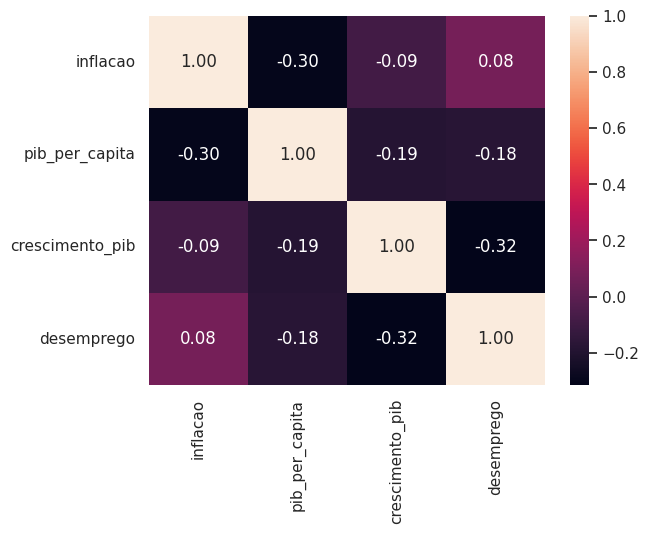

In [234]:
corr = df.corr()

sns.heatmap(corr, annot=True, fmt=".2f")

# O que podemos extrair dos dados?
- A inflação é uma variável que varia muito entre os países.
- O PIB per capita também varia muito.
- O crescimento do PIB varia de -10% a 10%.
- O desemprego varia de 1% a 20%.
- A correlação entre as variáveis é baixa, com valores que vão de -0,5 a 0,5.

Questão 2)

In [235]:
df_scaled = df.copy()
df_scaled.iloc[:, :] = StandardScaler().fit_transform(df)

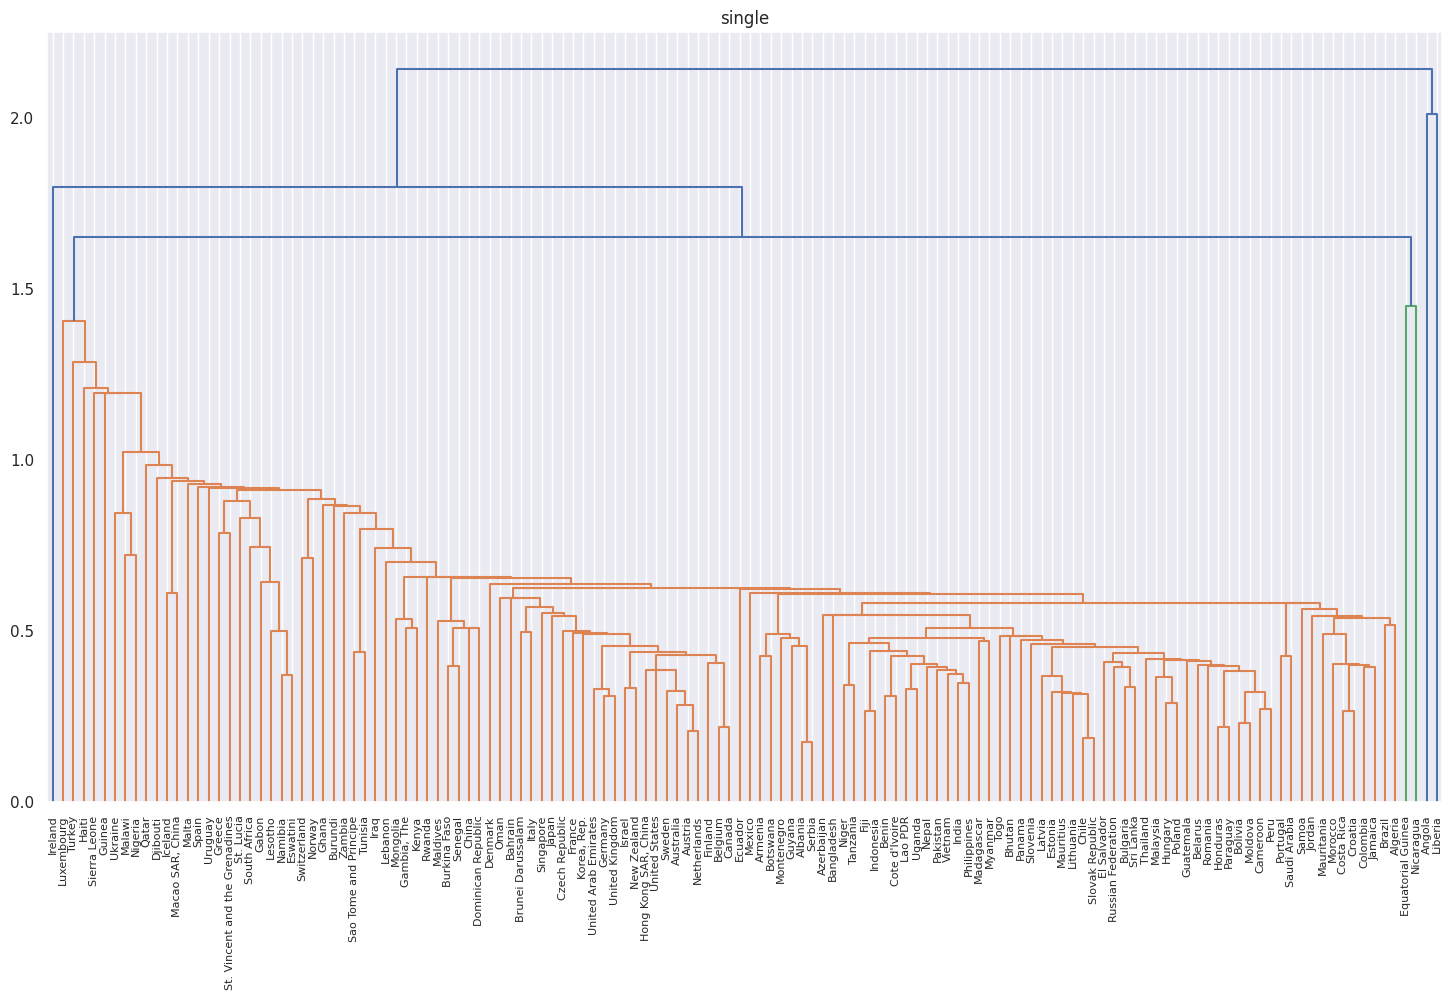

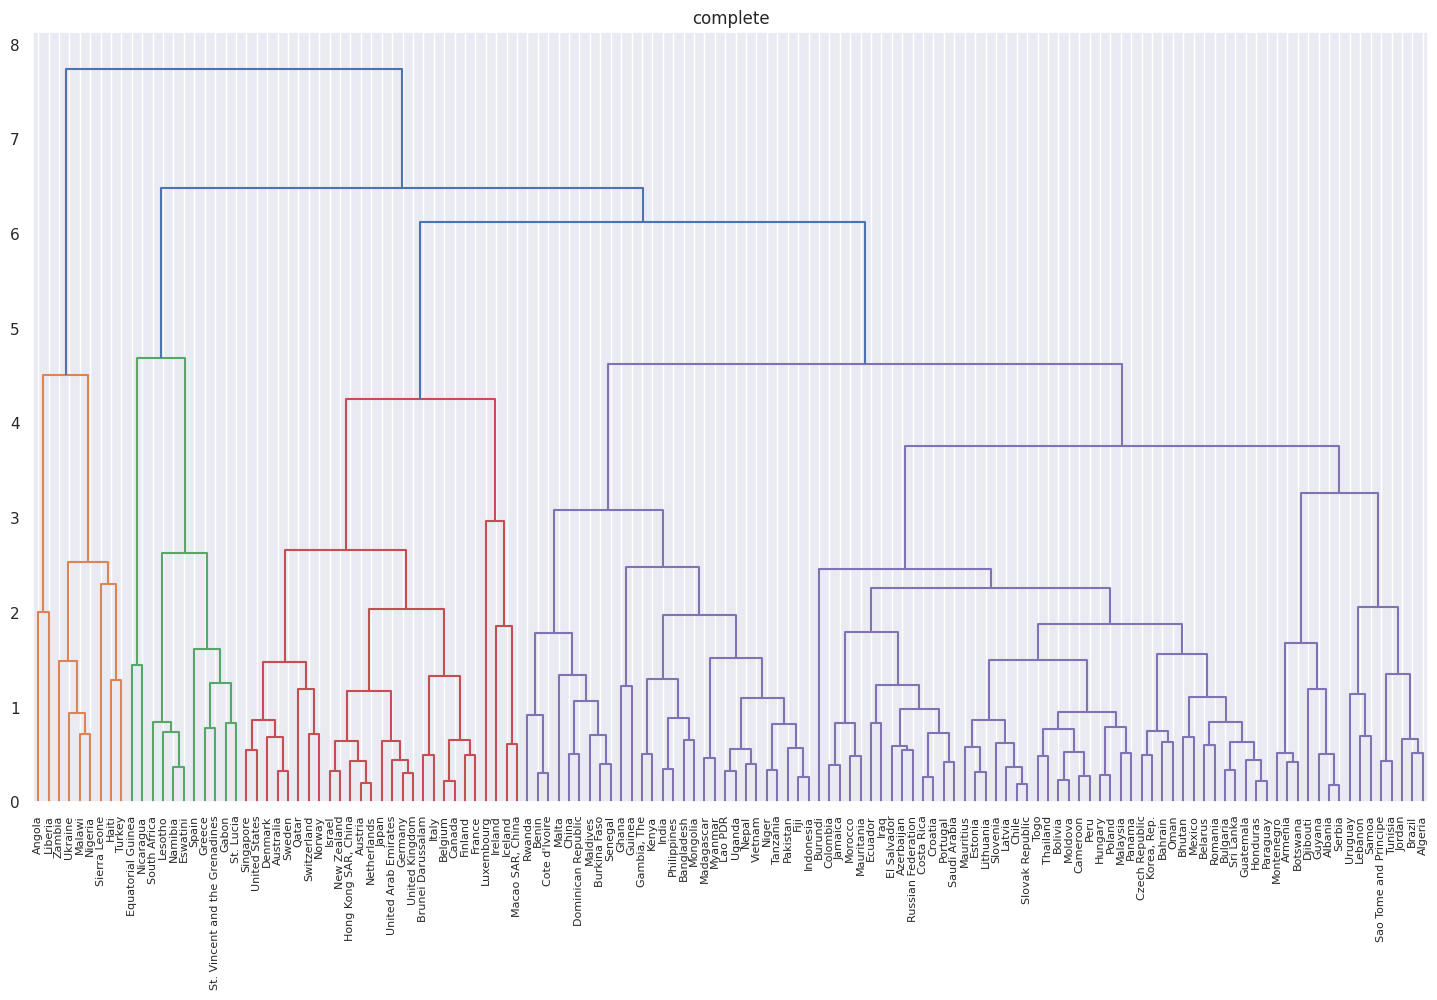

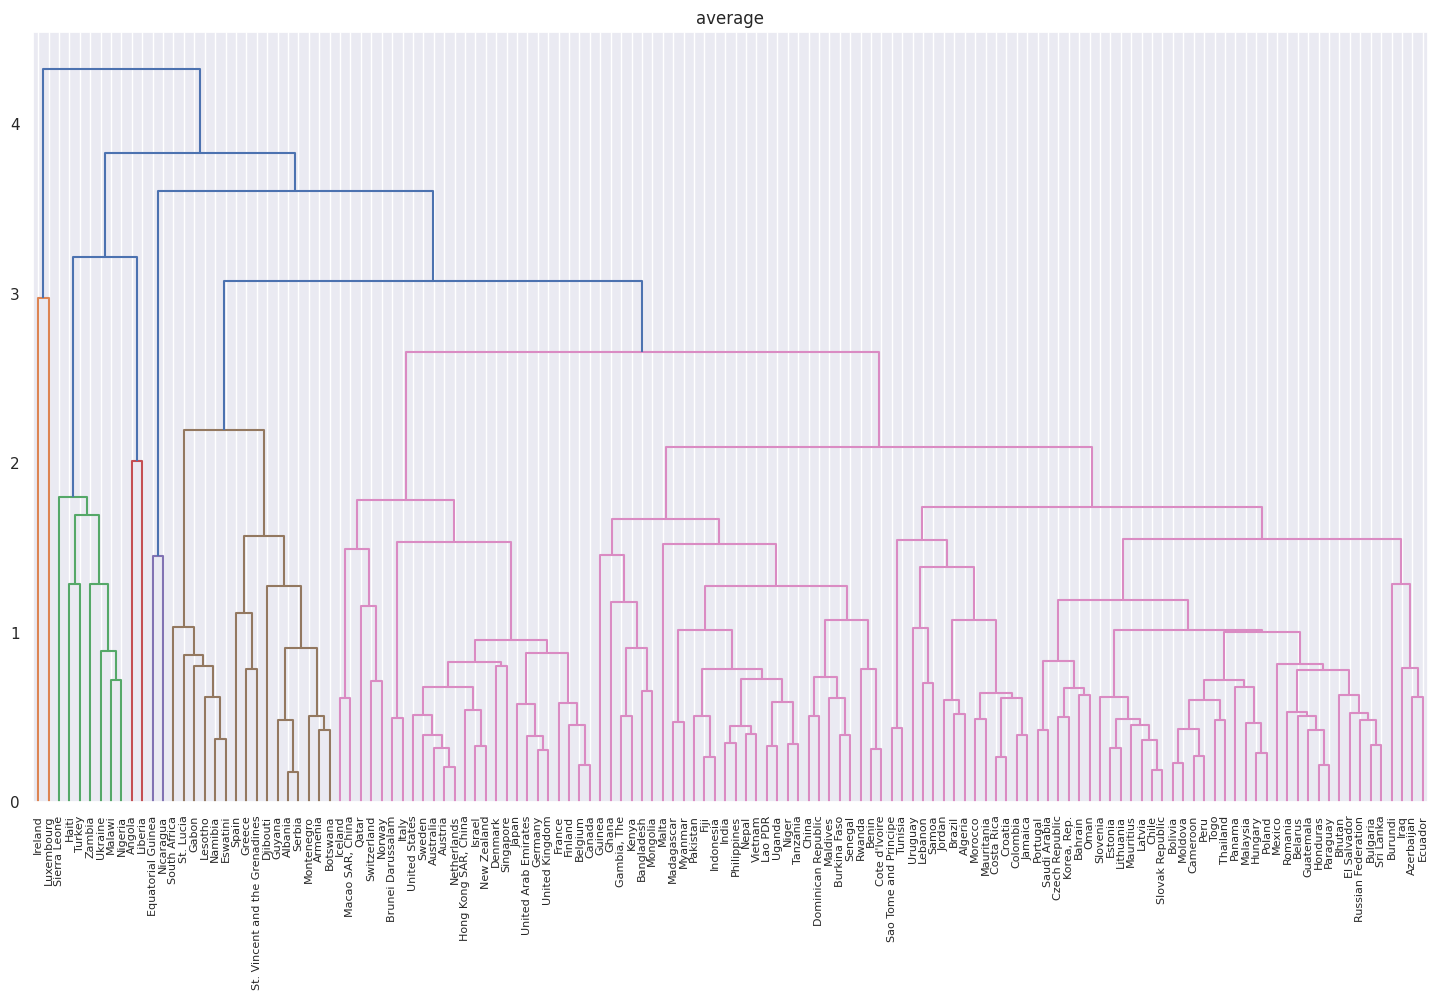

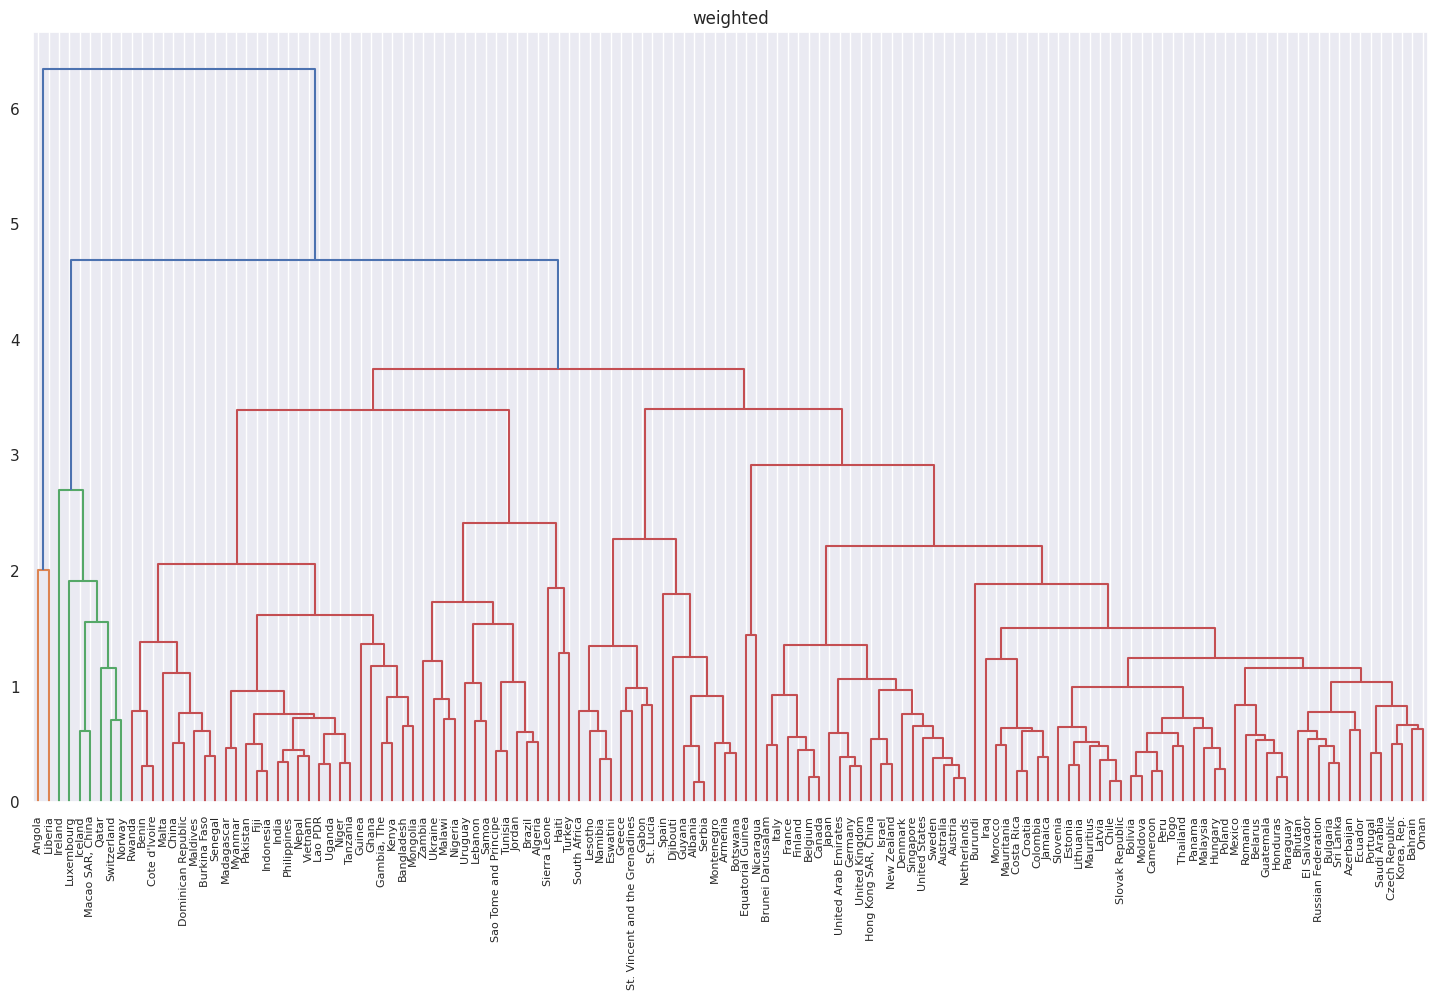

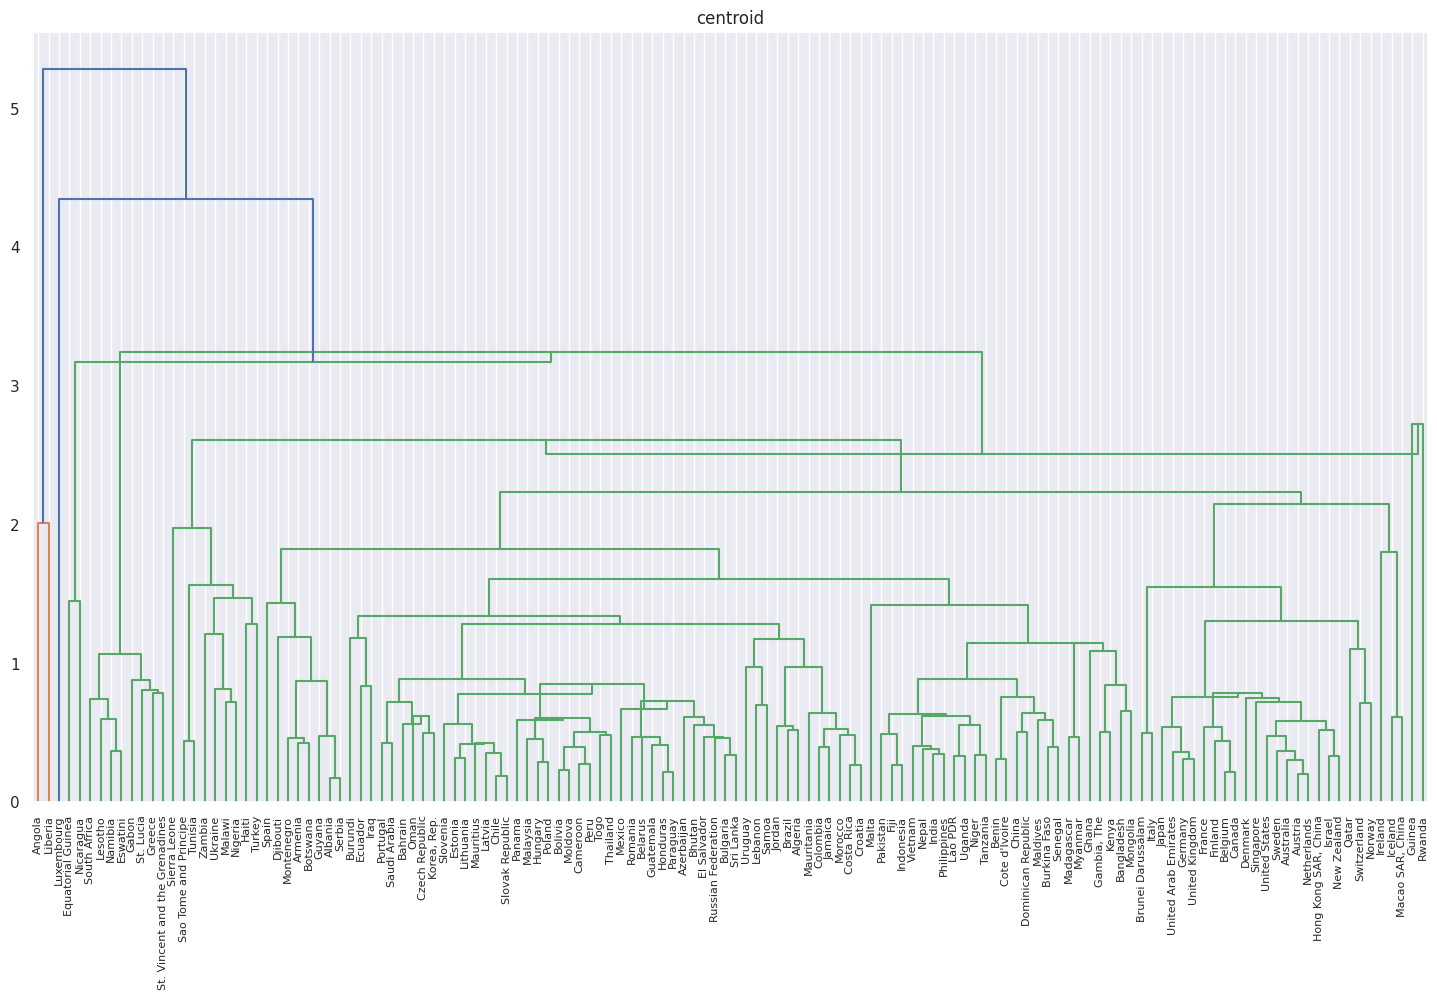

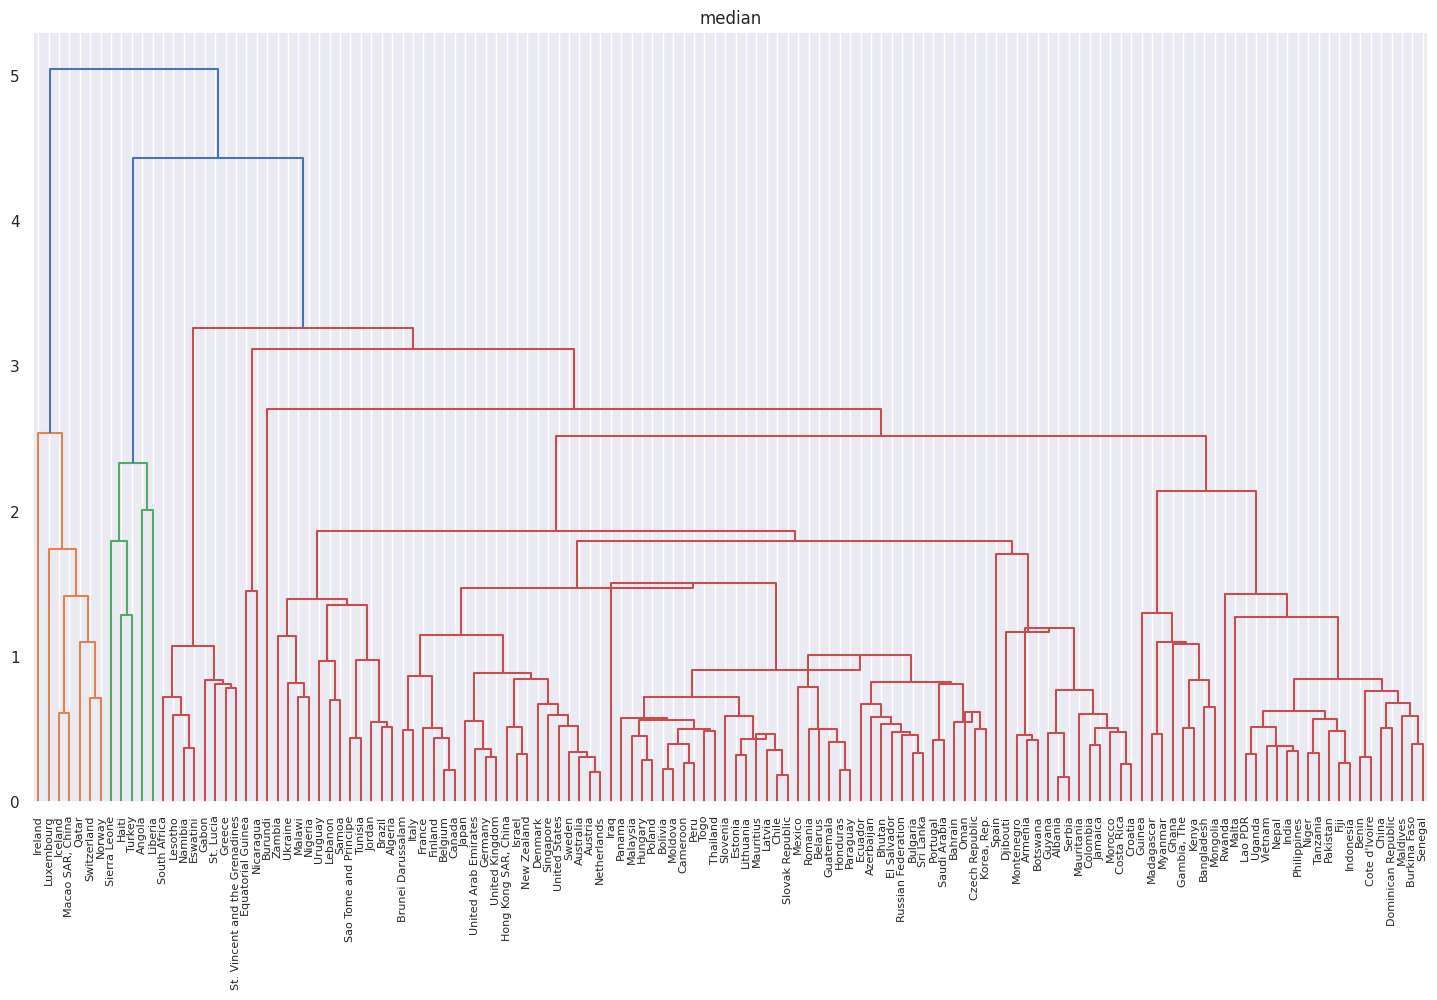

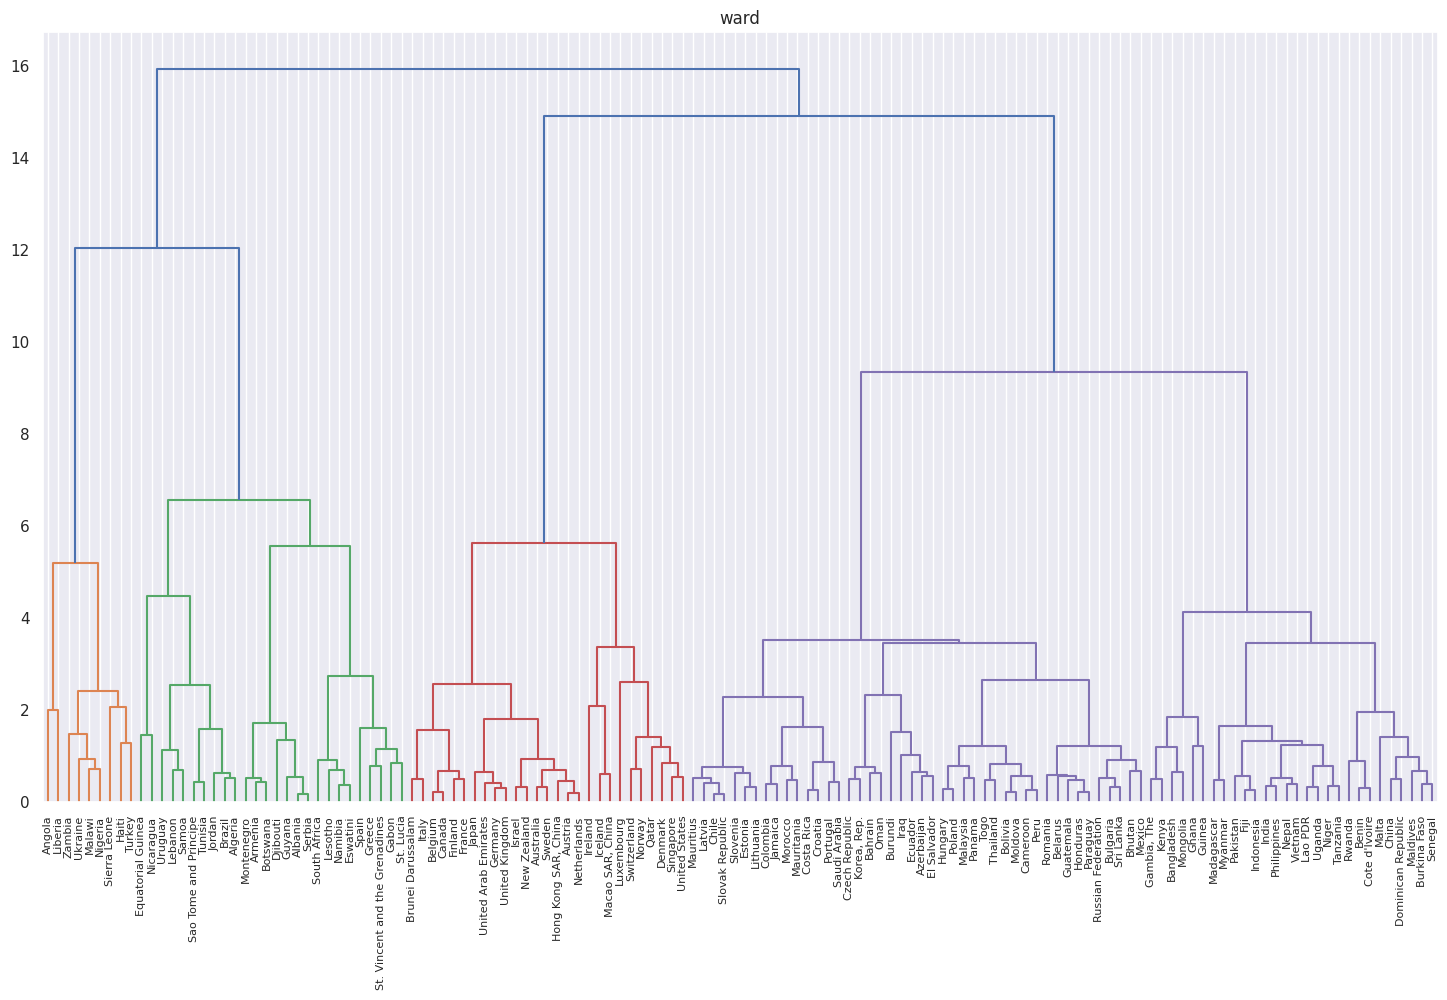

In [236]:
# O código abaixo considera o método do vizinho mais próximo na Análise de Agrupamento.
# Refaça o dendrograma considerando os outros métodos. Qual método ficou melhor para o estudo. Discuta.
# Quantos grupos é adequado? Justifique sua resposta, identificando qual foi o critério utilizado.

df_scaled = df.copy()
df_scaled.iloc[:, :] = StandardScaler().fit_transform(df)

methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'median', 'ward']

for method in methods:
    Z = hierarchy.linkage(df_scaled, method)
    plt.figure(figsize=(18, 10))
    plt.grid(axis='y')
    dn = hierarchy.dendrogram(Z, labels=list(df.index), leaf_font_size=8)
    plt.title(method)

- O método que ficou melhor foi o método de Ward, pois ele agrupou os países de forma mais clara e com menos grupos.
- O critério utilizado foi a distância entre os grupos, que foi a menor entre os métodos utilizados. Isso indica que os países foram agrupados de forma mais objetiva considerando suas situacões sócio-econômicas.
- Escolhemos fazer a divisão em 4 grupos, assim, descartando os agrupamentos com distância entre 8+.

Questão 3

In [237]:
paises_interesse = ['Brazil',
                    'China',
                    'Uruguay',
                    'Paraguay',
                    'Chile',
                    'Peru',
                    'Bolivia',
                    'Ecuador',
                    'Colombia',
                    'Germany',
                    'United States',
                    'United Kingdom',
                    'Poland']

df_paises = df_scaled.loc[paises_interesse, :]
print(df_paises.shape)


(13, 4)


In [238]:
# O código abaixo considera o método do vizinho mais próximo na Análise de Agrupamento.
# Refaça o dendrograma considerando os outros métodos. Qual método ficou melhor para o estudo. Discuta.
# Quantos grupos é adequado? Justifique sua resposta, identificando qual foi o critério utilizado.

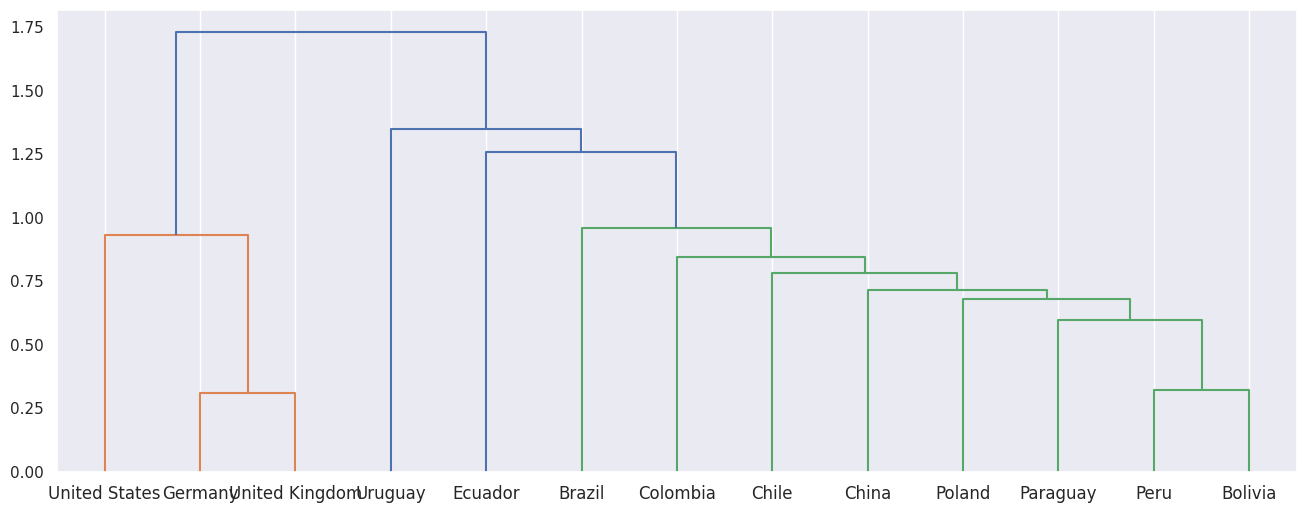

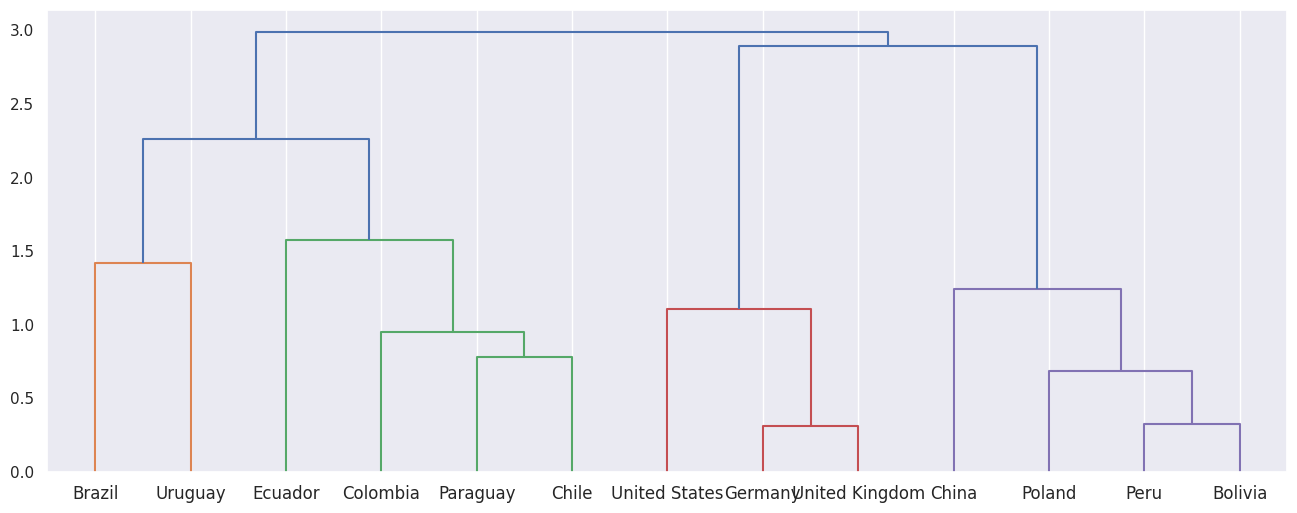

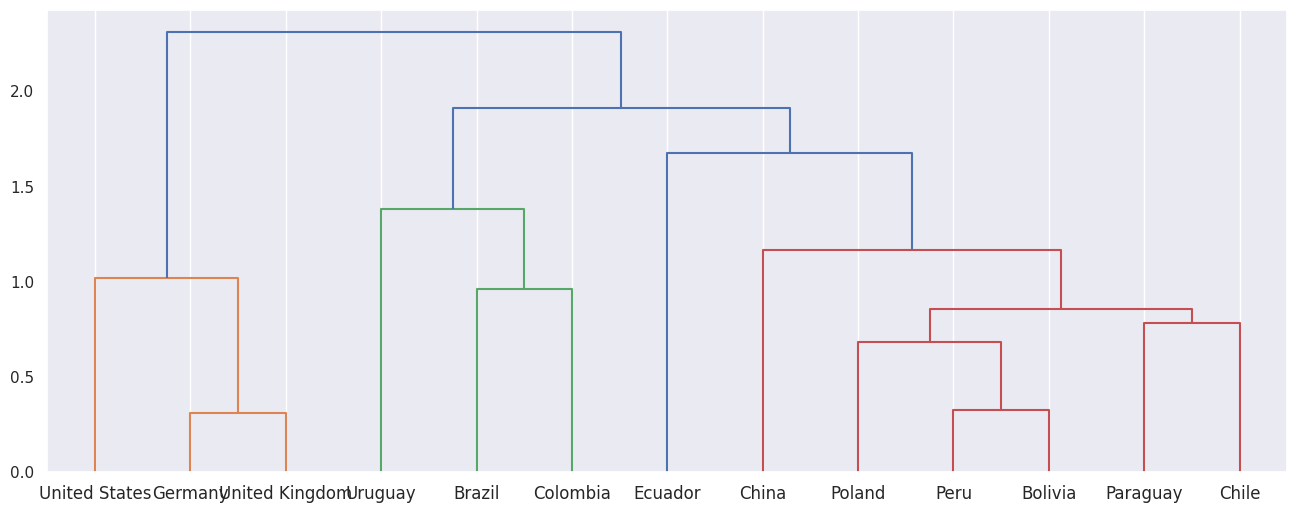

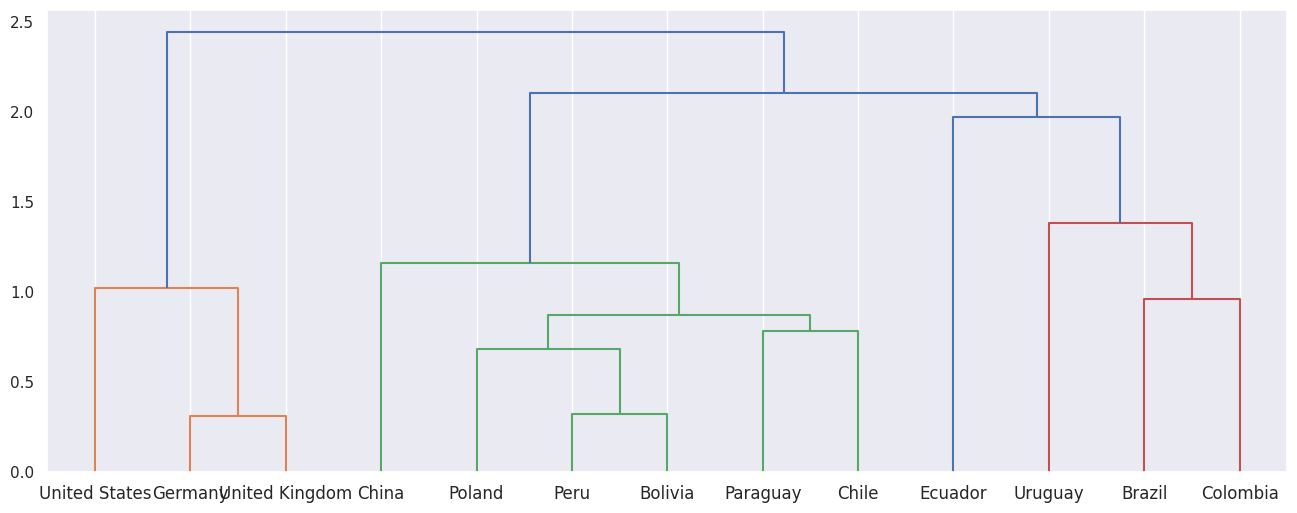

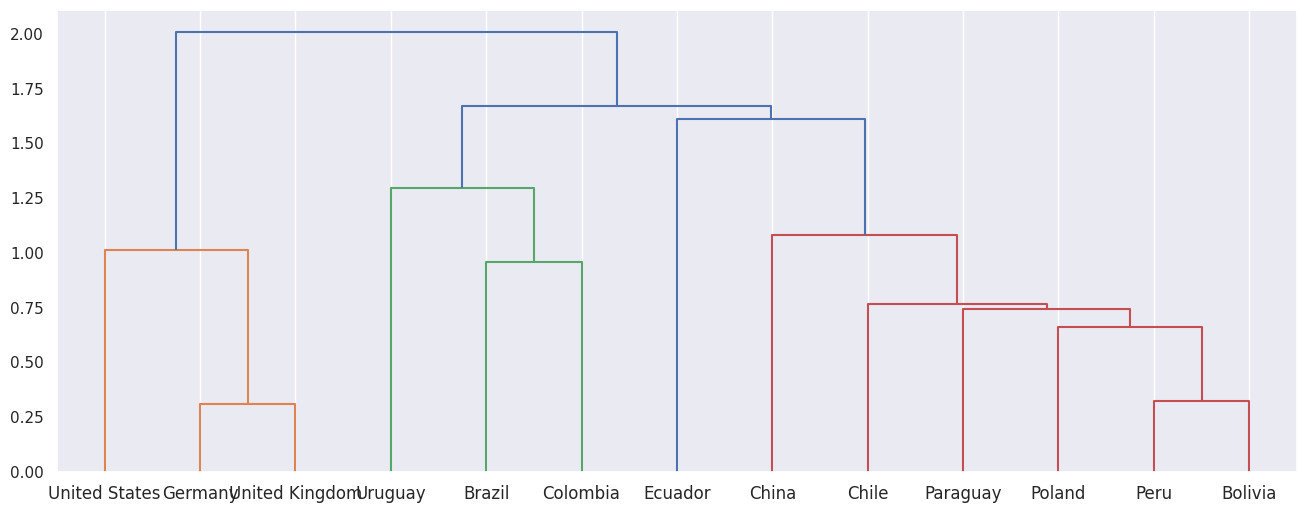

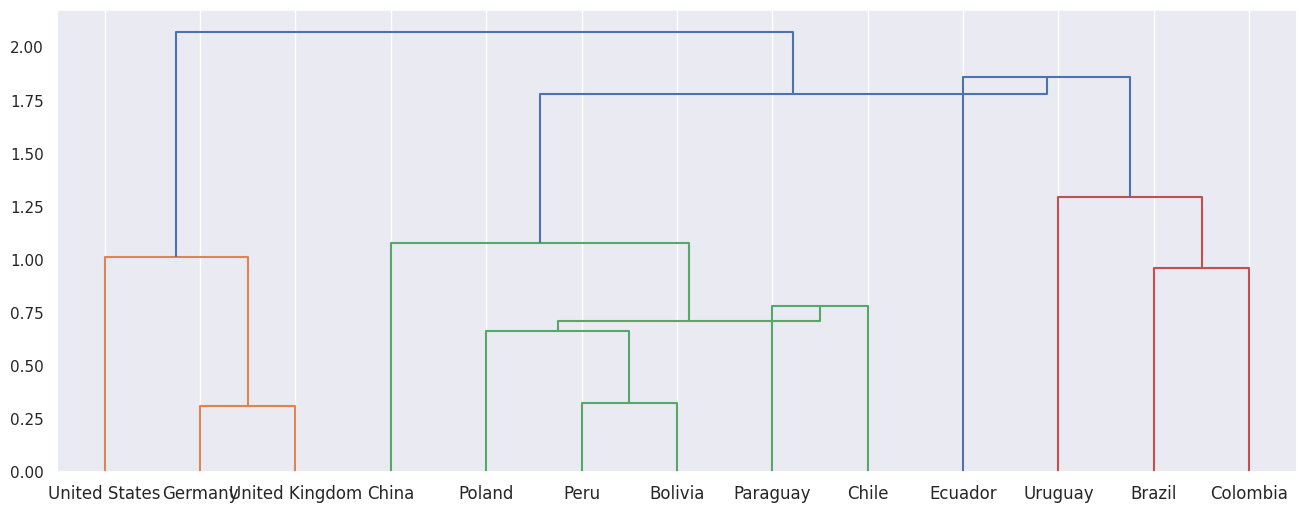

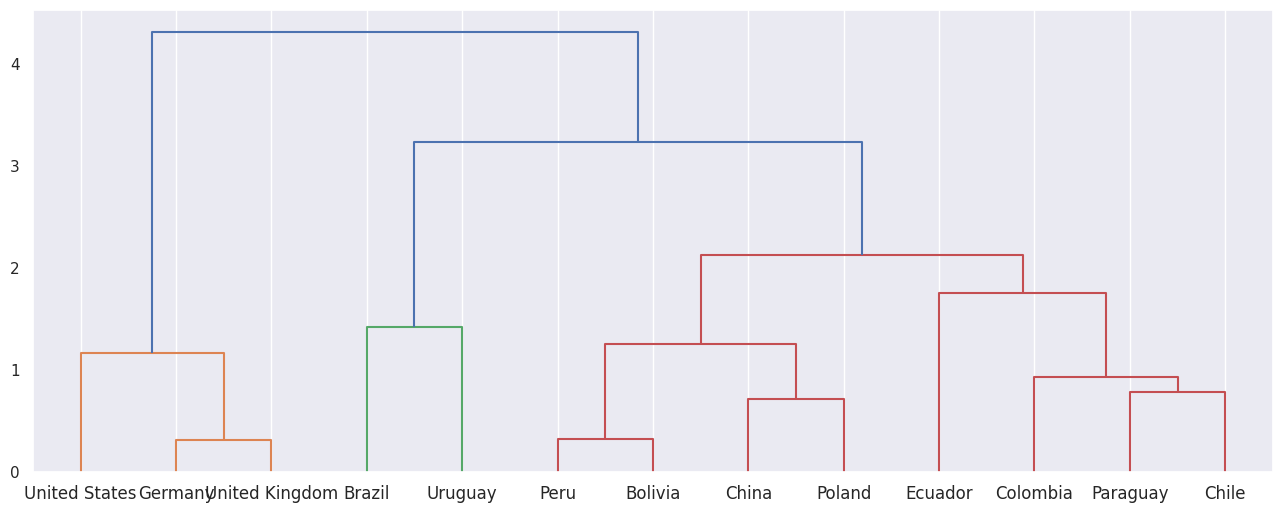

In [239]:

methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'median', 'ward']

for method in methods:
    Z = hierarchy.linkage(df_paises, method)
    plt.figure(figsize=(16, 6))
    plt.grid(axis='y')
    dn = hierarchy.dendrogram(Z, labels=list(df_paises.index), leaf_font_size=12)

- O método que ficou melhor foi o método de Ward, pois ele agrupou os países de forma mais clara e com menos grupos.
- O critério utilizado foi a distância entre os grupos, que foi a menor entre os métodos utilizados. Isso indica que os países foram agrupados de forma mais objetiva considerando suas situacões sócio-econômicas.
- Escolhemos fazer a divisão em 3 grupos, assim, descartando os agrupamentos com distância entre 2.5+.

In [240]:
# Complete com a quantidade de grupos que você optou. E também com o método utilizado para agrupar.
n_clusters = 3
cluster = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='complete')
groups = cluster.fit_predict(df_paises)

In [241]:
# Exibindo os elementos de cada grupo

countries = list(df_paises.index)
grouped_countries = {i: [] for i in range(n_clusters)}
for country, group in zip(countries, groups):
    grouped_countries[group].append(country)

for gp, ctr in grouped_countries.items():
    print(f'Cluster {gp}: {ctr}\n')

Cluster 0: ['Brazil', 'Uruguay', 'Paraguay', 'Chile', 'Ecuador', 'Colombia']

Cluster 1: ['China', 'Peru', 'Bolivia', 'Poland']

Cluster 2: ['Germany', 'United States', 'United Kingdom']



In [242]:
# incluir no dataframe de dados as informações sobre a qual grupo cada observação pertence
df_paises['grupo']=groups
df_paises

,inflacao,pib_per_capita,crescimento_pib,desemprego,grupo
Brazil,0.027255,-0.383314,-1.031658,1.064347,0
China,-0.393019,-0.345756,1.437407,-0.453816,1
Uruguay,1.069095,-0.014079,-0.805350,0.208221,0
Paraguay,0.109393,-0.518037,0.103361,-0.398709,0
Chile,-0.297840,-0.073928,0.277573,0.070359,0
Peru,-0.593142,-0.470507,0.255887,-0.747660,1
Bolivia,-0.340878,-0.620666,0.367182,-0.670323,1
Ecuador,-1.000647,-0.497121,-0.914768,-0.548526,0
Colombia,-0.084976,-0.483583,-0.337859,0.419684,0
Germany,-0.483579,1.351911,-0.893071,-0.639126,2


In [243]:
# Calcule a média, a mediana e o desvio padrão de cada grupo. Que informação interessante você observa em cada grupo.
df_paises.groupby('grupo').agg(['mean', 'median', 'std'])

inflacao                     pib_per_capita                      \
           mean    median       std           mean    median       std   
grupo                                                                    
0     -0.029620 -0.028861  0.670468      -0.328344 -0.433449  0.225867   
1     -0.447316 -0.427623  0.109186      -0.383229 -0.408132  0.222040   
2     -0.371590 -0.335385  0.098983       1.480645  1.351911  0.458871   

      crescimento_pib                     desemprego                      
                 mean    median       std       mean    median       std  
grupo                                                                     
0           -0.451450 -0.571605  0.552945   0.135896  0.139290  0.584178  
1            0.711155  0.575662  0.534900  -0.616149 -0.631561  0.125336  
2           -0.682304 -0.893071  0.375913  -0.574554 -0.544229  0.055956

# Informações sobre as variáveis
- Grupo 0: Brasil, Uruguai, Paraguai, Chile, Ecuador, Colombia
- Grupo 1: China, Peru, Bolivia, Polonia
- Grupo 2: Alemanha, Estados Unidos, Reino Unido

---

- Grupo 0: Países com inflação média, PIB per capita médio, crescimento do PIB médio e desemprego médio.
- Grupo 1: Países com inflação baixa, PIB per capita baixo, crescimento do PIB baixo e desemprego alto.
- Grupo 2: Países com inflação baixa, PIB per capita alto, crescimento do PIB alto e desemprego baixo.